# Inspect the MaMMoS magnetic-SANS data products

This notebook reads a generated HDF5 product through `mammos_entity` and keeps each entity's ontology label, unit, description, and numerical value together. The stored data follow the reduced data path

$$\bigl(\mathbf M_0,\psi\bigr) \longrightarrow \bigl(\Gamma_\perp,\Gamma_\parallel,\Gamma_\times\bigr) \longrightarrow I_{\mathrm M}.$$

Generate both data products with `pixi run data`, then launch this notebook with `pixi run notebook`.

In [134]:
from pathlib import Path

import mammos_entity as me
import matplotlib.pyplot as plt
import numpy as np

path = Path.cwd() / "output/data/data1.h5"

# Read data using mammos-entity

In [135]:
data = me.from_hdf5(path)

for name, item in data:
    print(name)

correlation_spectra
magnetic_SANS_cross_sections
metadata
model
orientation_distributions
real_space_field
validation


# Inspect the properties of the affine magnetization model

In [136]:
for name, item in data["model"]:
    print(name)
    print("  ", data["model"][name])

radius
   ISQDimensionlessQuantity(value=1.0, description='Sphere radius in the internal normalized length convention.')
m0
   ISQDimensionlessQuantity(value=[0. 0. 1.], description='Constant term m_0 of the affine magnetization field in normalized model amplitude.')
m1
   ISQDimensionlessQuantity(value=
[[ 0. -7.  0.]
 [ 7.  0. -0.]
 [-0.  0.  0.]],
 description='First-order matrix m_1 of the affine magnetization field in the internal normalized coordinate and amplitude convention.')
zeta
   ISQDimensionlessQuantity(value=0.0, description='Scalar part zeta = Tr(m_1)/3 of the first-order matrix.')
symmetric_traceless
   ISQDimensionlessQuantity(value=
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]],
 description='Symmetric-traceless part S of the first-order matrix m_1.')
omega
   ISQDimensionlessQuantity(value=[0. 0. 7.], description='Axial vector omega of the antisymmetric part [omega]_cross of m_1.')


# Inspect and vizualize the correlation spectra

In [137]:
gamma_spec = data["correlation_spectra"]
for name, item in gamma_spec:
    print(name)

qR
Gamma_perp
Gamma_parallel
Gamma_cross


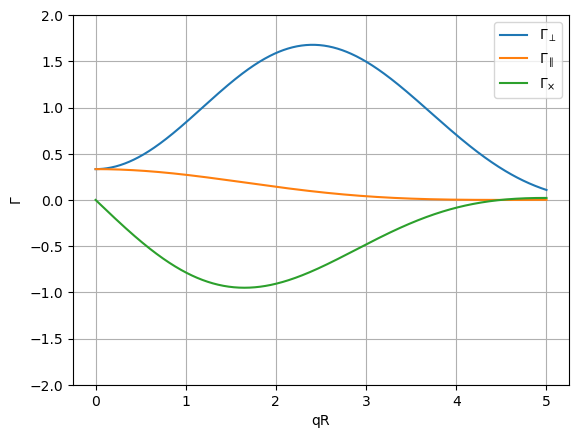

In [138]:
plt.plot(gamma_spec["qR"].value, gamma_spec["Gamma_perp"].value, label=r"$\Gamma_{\perp}$")
plt.plot(gamma_spec["qR"].value, gamma_spec["Gamma_parallel"].value, label=r"$\Gamma_{\parallel}$")
plt.plot(gamma_spec["qR"].value, gamma_spec["Gamma_cross"].value, label=r"$\Gamma_{\times}$")
plt.grid()
plt.legend()
plt.ylim(-2, 2)
plt.xlabel(r"qR")
plt.ylabel(r"$\Gamma$")
plt.show()

# Inspect and visualize the magnetic SANS data

In [139]:
magSANS_cs = data["magnetic_SANS_cross_sections"]
for name, item in magSANS_cs:
    print(name)

qR_edges
theta_edges_radian
qR_centers
theta_centers_radian
qzR_edges
qyR_edges
I_sf_raw
I_chi_raw


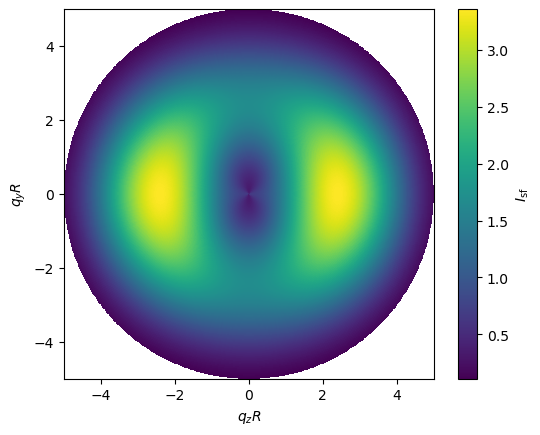

In [140]:
fig, ax = plt.subplots()
mesh = ax.pcolormesh(
    magSANS_cs["qzR_edges"].q,
    magSANS_cs["qyR_edges"].q,
    magSANS_cs["I_sf_raw"].q,
    shading="flat",
)
fig.colorbar(mesh, ax=ax, label=r"$I_{\mathrm{sf}}$")
ax.set(xlabel=r"$q_zR$", ylabel=r"$q_yR$", aspect="equal")
plt.show()

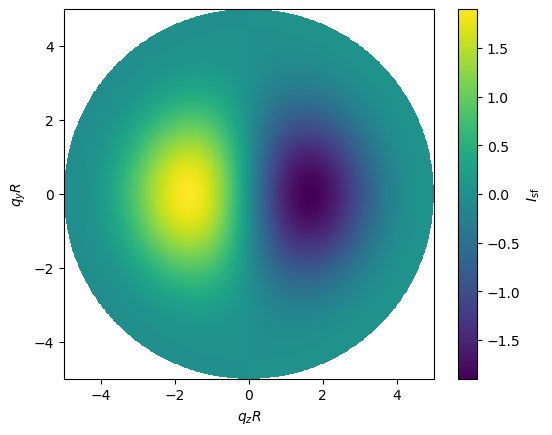

In [141]:
fig, ax = plt.subplots()
mesh = ax.pcolormesh(
    magSANS_cs["qzR_edges"].q,
    magSANS_cs["qyR_edges"].q,
    magSANS_cs["I_chi_raw"].q,
    shading="flat",
)
fig.colorbar(mesh, ax=ax, label=r"$I_{\mathrm{sf}}$")
ax.set(xlabel=r"$q_zR$", ylabel=r"$q_yR$", aspect="equal")
plt.show()